In [49]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Input
from tensorflow.keras.optimizers import SGD
train = pd.read_csv(r"D:\Downloads\DL DATASET\cifar10\train.csv")
test = pd.read_csv(r"D:\Downloads\DL DATASET\cifar10\test.csv")



In [47]:
X_train = train.drop('label', axis=1).values
y_train = train['label'].values

X_test = test.values

In [48]:
# Normalize data
X_train = X_train / 255.0
X_test = X_test / 255.0

In [65]:
# c. Define Feedforward Neural Network
model = Sequential([
    Input(shape=(3072,)),
    Dense(512, activation='relu'),
    Dense(256, activation='relu'),
    Dense(10, activation='softmax')
])


In [66]:
# d. Compile and train using SGD
model.compile(
    optimizer=SGD(learning_rate=0.01),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [67]:
history = model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.2
)


Epoch 1/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 16s 13ms/step - accuracy: 0.3273 - loss: 1.8816 - val_accuracy: 0.3748 - val_loss: 1.7769
Epoch 2/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 18s 11ms/step - accuracy: 0.4006 - loss: 1.6938 - val_accuracy: 0.4058 - val_loss: 1.6687
Epoch 3/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 22s 11ms/step - accuracy: 0.4285 - loss: 1.6142 - val_accuracy: 0.4409 - val_loss: 1.6084
Epoch 4/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 21s 12ms/step - accuracy: 0.4482 - loss: 1.5558 - val_accuracy: 0.4381 - val_loss: 1.5903
Epoch 5/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 20s 11ms/step - accuracy: 0.4639 - loss: 1.5129 - val_accuracy: 0.4521 - val_loss: 1.5425
Epoch 6/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 14s 12ms/step - accuracy: 0.4804 - loss: 1.4719 - val_accuracy: 0.4601 - val_loss: 1.5271
Epoch 7/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 21s 12ms/step - accuracy: 0.4913 - loss: 1.4382 - val_accuracy: 0.4709 - val_loss: 1.5042
Epoch 8/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 20s 12ms/step - accuracy: 0.5030 -

In [68]:

# e. Evaluate the model
loss, accuracy = model.evaluate(X_train, y_train)

1563/1563 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - accuracy: 0.6006 - loss: 1.1426


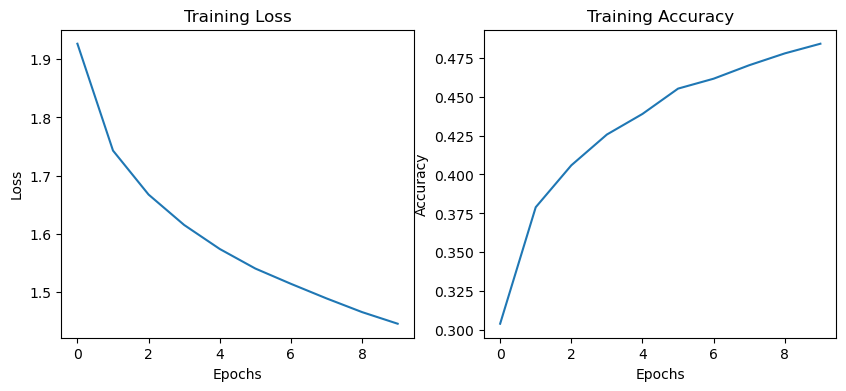

In [62]:
# f. Plot training loss and accuracy
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'])
plt.title("Training Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'])
plt.title("Training Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")

plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 178ms/step


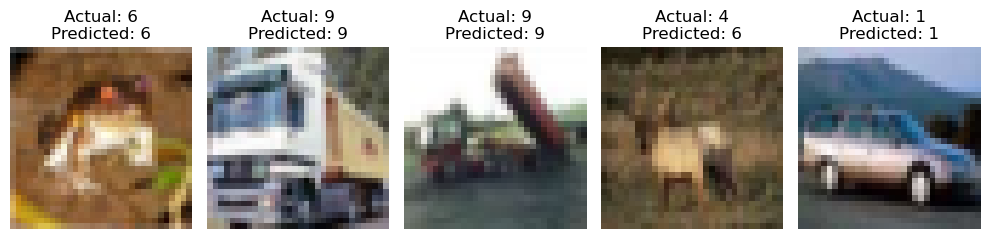

In [69]:
# Display sample predictions
predictions = model.predict(X_train[:5])
predicted_labels = np.argmax(predictions, axis=1)

plt.figure(figsize=(10, 4))

for i in range(5):
    image = X_train[i].reshape(3, 32, 32).transpose(1, 2, 0)

    plt.subplot(1, 5, i + 1)
    plt.imshow(image)
    plt.title("Actual: " + str(y_train[i]) +
              "\nPredicted: " + str(predicted_labels[i]))
    plt.axis('off')

plt.tight_layout()
plt.show()